# Семинар 9. Оптимизация на множествах простой структуры

$$\min_{x \in Q} f(x), \qquad f \text{ — гладкая выпуклая}$$

План:

1) Два определения «простого множества»: проекция и линейный минимизирующий оракул
2) Метод проекции градиента
3) Метод условного градиента (Франк–Вольф)
4) Эксперименты, в том числе шар ядерной нормы

In [1]:
import time

import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.figsize": (11, 4.2), "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 11, "lines.linewidth": 1.8, "figure.dpi": 110})

## 1. Два определения простоты

**v.1 (проекция).** Множество $Q$ простое, если дёшево решается

$$\pi_Q(y) = \arg\min_{x \in Q} \|x - y\|_2.$$

**v.2 (линейный оракул, LMO).** Множество $Q$ простое, если дёшево решается

$$s(g) = \arg\min_{x \in Q} \langle g, x\rangle.$$

Определения не совпадают. Для неограниченного $Q$ линейная задача может быть
неограниченной снизу (например $Q = \mathbb{R}^n_+$), хотя проекция тривиальна.
В обратную сторону: на шаре ядерной нормы проекция требует полного SVD,
а LMO — только старшей сингулярной пары.

### 1.1. Проекции

In [2]:
def proj_box(y, lo=0.0, hi=1.0):
    return np.clip(y, lo, hi)


def proj_simplex(y, r=1.0):
    """Проекция на {x >= 0, sum x = r}. Сортировка, O(n log n)."""
    u = np.sort(y)[::-1]
    css = np.cumsum(u) - r
    idx = np.arange(1, y.size + 1)
    cond = u - css / idx > 0
    rho = idx[cond][-1]
    theta = css[rho - 1] / rho
    return np.maximum(y - theta, 0.0)


def proj_l1(y, r=1.0):
    """Проекция на шар l1: если точка вне шара, проецируем |y| на симплекс."""
    if np.abs(y).sum() <= r:
        return y.copy()
    return np.sign(y) * proj_simplex(np.abs(y), r)


def proj_l2(y, r=1.0):
    nrm = np.linalg.norm(y)
    return y if nrm <= r else y * (r / nrm)


def proj_nuclear(Y, r=1.0):
    """Проекция на шар ядерной нормы: полное SVD + проекция спектра на шар l1."""
    U, sv, Vt = np.linalg.svd(Y, full_matrices=False)
    return (U * proj_l1(sv, r)) @ Vt

In [3]:
y = np.array([0.3, -1.4, 2.0, 0.1])
print("box   ", proj_box(y))
print("симплекс", proj_simplex(y), " сумма =", proj_simplex(y).sum())
print("l1    ", proj_l1(y, 1.0), " ||.||_1 =", np.abs(proj_l1(y, 1.0)).sum())
print("l2    ", proj_l2(y, 1.0), " ||.||_2 =", np.linalg.norm(proj_l2(y, 1.0)))

box    [0.3 0.  1.  0.1]
симплекс [0. 0. 1. 0.]  сумма = 1.0
l1     [ 0.  -0.2  0.8  0. ]  ||.||_1 = 1.0
l2     [ 0.1219 -0.5687  0.8124  0.0406]  ||.||_2 = 0.9999999999999998


Проверка свойства проекции: $\langle y - \pi_Q(y),\, x - \pi_Q(y)\rangle \le 0$
для всех $x \in Q$.

In [4]:
rng = np.random.default_rng(0)
y = rng.normal(size=50) * 3
p = proj_simplex(y)
xs = np.array([proj_simplex(rng.normal(size=50)) for _ in range(2000)])
print("максимум скалярного произведения:", np.max((xs - p) @ (y - p)))

максимум скалярного произведения: 4.6629367034256575e-15


### 1.2. Линейные оракулы

Решение линейной задачи на выпуклом компакте всегда достигается в крайней точке,
поэтому LMO — это «выбор нужной вершины».

In [5]:
def lmo_box(g, lo=0.0, hi=1.0):
    return np.where(g <= 0, hi, lo).astype(float)


def lmo_simplex(g, r=1.0):
    s = np.zeros_like(g)
    s[np.argmin(g)] = r
    return s


def lmo_l1(g, r=1.0):
    s = np.zeros_like(g)
    i = np.argmax(np.abs(g))
    s[i] = -r * np.sign(g[i])
    return s


def lmo_l2(g, r=1.0):
    return -r * g / max(np.linalg.norm(g), 1e-30)


def lmo_nuclear(G, r=1.0):
    """Старшая сингулярная пара: s = -r * u1 v1^T. Возвращаем множители."""
    u, _, vt = spla.svds(G, k=1, tol=1e-6)
    return -r * u[:, 0], vt[0]

## 2. Метод проекции градиента

$$x_{k+1} = \pi_Q\bigl(x_k - \alpha_k \nabla f(x_k)\bigr)$$

**Критерий остановки.** Норма градиента бессмысленна: в решении на границе
$\nabla f(x^*) \ne 0$. Правильная величина — градиентное отображение

$$G_\alpha(x) = \frac{1}{\alpha}\bigl(x - \pi_Q(x - \alpha\nabla f(x))\bigr),$$

оно равно нулю тогда и только тогда, когда $x$ — решение, и при $Q=\mathbb{R}^n$
совпадает с градиентом.

Линейный поиск: условие Армихо записывается через фактически сделанный шаг

$$f(x_k(\alpha)) \le f(x_k) + c_1\langle \nabla f(x_k), x_k(\alpha) - x_k\rangle,
\qquad x_k(\alpha) = \pi_Q(x_k - \alpha \nabla f(x_k)).$$

In [6]:
class Trace:
    def __init__(self, name):
        self.name = name
        self.t0 = time.perf_counter()
        self.rows = []

    def add(self, f, crit, extra=0.0):
        self.rows.append((time.perf_counter() - self.t0, f, crit, extra))

    def __getattr__(self, item):
        cols = {"t": 0, "fs": 1, "crit": 2, "extra": 3}
        if item in cols:
            return np.array(self.rows)[:, cols[item]]
        raise AttributeError(item)

    @property
    def niter(self):
        return len(self.rows) - 1


def projected_gd(f, gradf, proj, x0, alpha=None, armijo=False, c1=0.1, rho=0.5,
                 tol=1e-8, max_iter=1000, name="PG", extra=None):
    x = np.array(x0, dtype=float)
    tr = Trace(name)
    for k in range(max_iter):
        g = gradf(x)
        a = alpha(k) if callable(alpha) else alpha
        if armijo:
            fx = f(x)
            for _ in range(50):
                xn = proj(x - a * g)
                if f(xn) <= fx + c1 * g @ (xn - x):
                    break
                a *= rho
        else:
            xn = proj(x - a * g)
        crit = np.linalg.norm(x - xn) / (a if not callable(alpha) else a)
        tr.add(f(x), crit, extra(x) if extra else 0.0)
        x = xn
        if crit <= tol:
            break
    tr.add(f(x), crit, extra(x) if extra else 0.0)
    return x, tr

## 3. Метод условного градиента (Франк–Вольф)

$$s_k = \arg\min_{s \in Q}\langle \nabla f(x_k), s\rangle, \qquad
x_{k+1} = x_k + \alpha_k (s_k - x_k), \quad \alpha_k \in [0,1].$$

Итерация остаётся в $Q$ как выпуклая комбинация, проекция не нужна вообще.

**Зазор Франка–Вольфа.** Из выпуклости

$$f(x^*) \ge f(x_k) + \langle \nabla f(x_k), x^* - x_k\rangle
\ge f(x_k) + \langle \nabla f(x_k), s_k - x_k\rangle,$$

значит

$$g_k = \langle \nabla f(x_k), x_k - s_k\rangle \ge f(x_k) - f(x^*) \ge 0.$$

Это бесплатная верхняя оценка невязки по функции: $s_k$ всё равно уже посчитан.
У метода проекции градиента такого сертификата нет.

In [7]:
def frank_wolfe(f, gradf, lmo, x0, step="2/(k+2)", tol=1e-8, max_iter=1000,
                name="FW", extra=None, exact=None, c1=0.1, rho=0.5):
    x = np.array(x0, dtype=float)
    tr = Trace(name)
    for k in range(max_iter):
        g = gradf(x)
        s = lmo(g)
        d = s - x
        gap = -float(g @ d)
        tr.add(f(x), gap, extra(x) if extra else 0.0)
        if gap <= tol:
            break
        if step == "2/(k+2)":
            a = 2.0 / (k + 2)
        elif step == "exact":
            a = exact(x, d)
        elif step == "armijo":
            a, fx = 1.0, f(x)
            for _ in range(50):
                if f(x + a * d) <= fx + c1 * a * (g @ d):
                    break
                a *= rho
        else:
            a = float(step)
        x = x + min(max(a, 0.0), 1.0) * d
    tr.add(f(x), gap, extra(x) if extra else 0.0)
    return x, tr


def plot_traces(traces, fstar=None, ylabel=None, xaxis="iter", ax=None, title=None):
    ax = ax or plt.gca()
    for tr in traces:
        ys = tr.fs - fstar if fstar is not None else tr.crit
        xs = np.arange(len(tr.fs)) if xaxis == "iter" else tr.t
        ax.loglog(np.arange(1, len(ys) + 1) if xaxis == "iter" else np.maximum(xs, 1e-6),
                  np.maximum(ys, 1e-16), label=tr.name)
    ax.set_xlabel("итерация" if xaxis == "iter" else "время, с")
    ax.set_ylabel(ylabel or (r"$f(x_k) - f^*$" if fstar is not None else "критерий"))
    if title:
        ax.set_title(title)
    ax.legend(fontsize=9)

## 4. Эксперимент 1: квадратичная задача на кубе

$$\min_{0 \le x \le 1} \tfrac12\|Ax - b\|_2^2$$

In [8]:
rng = np.random.default_rng(1)
n, m = 200, 400                      # m > n: безусловный минимум единственный
A = rng.normal(size=(m, n))
x_true = rng.normal(size=n)          # часть компонент вне куба, ограничения активны
b = A @ x_true + 0.1 * rng.normal(size=m)
L = np.linalg.eigvalsh(A.T @ A).max()

f = lambda x: 0.5 * np.linalg.norm(A @ x - b) ** 2
gradf = lambda x: A.T @ (A @ x - b)
x0 = np.zeros(n)


def exact_quad(x, d):
    Ad = A @ d
    denom = Ad @ Ad
    if denom <= 0:
        return 0.0
    return float(np.clip(-(A @ x - b) @ Ad / denom, 0, 1))


x_ref, _ = projected_gd(f, gradf, proj_box, x0, alpha=1 / L, max_iter=50000, tol=1e-14)
fstar = f(x_ref)
print(f"опорное значение f* = {fstar:.6f}, активных ограничений "
      f"{int(np.sum((x_ref < 1e-9) | (x_ref > 1 - 1e-9)))} из {n}")

res = [projected_gd(f, gradf, proj_box, x0, alpha=1 / L, max_iter=2000, name="PG, 1/L"),
       projected_gd(f, gradf, proj_box, x0, alpha=lambda k: 1 / (k + 1), max_iter=2000,
                    name="PG, 1/k"),
       projected_gd(f, gradf, proj_box, x0, alpha=1.0, armijo=True, max_iter=2000,
                    name="PG, Армихо"),
       frank_wolfe(f, gradf, lmo_box, x0, step="2/(k+2)", max_iter=2000, name="FW, 2/(k+2)"),
       frank_wolfe(f, gradf, lmo_box, x0, step="armijo", max_iter=2000, name="FW, Армихо"),
       frank_wolfe(f, gradf, lmo_box, x0, step="exact", exact=exact_quad, max_iter=2000,
                   name="FW, точный шаг")]
fstar = min([fstar] + [tr.fs.min() for _, tr in res])
print(f"{'метод':>16} {'итераций':>9} {'f - f*':>12} {'время, с':>10}")
for _, tr in res:
    print(f"{tr.name:>16} {tr.niter:9d} {tr.fs[-1] - fstar:12.3e} {tr.t[-1]:10.2f}")

опорное значение f* = 22055.178943, активных ограничений 138 из 200
           метод  итераций       f - f*   время, с
         PG, 1/L       163    7.276e-12       0.01
         PG, 1/k       455    7.276e-12       0.03
      PG, Армихо       290    0.000e+00       0.28
     FW, 2/(k+2)      2000    4.471e-03       0.10
      FW, Армихо      2000    5.668e-01       0.50
  FW, точный шаг      2000    1.144e+00       0.17


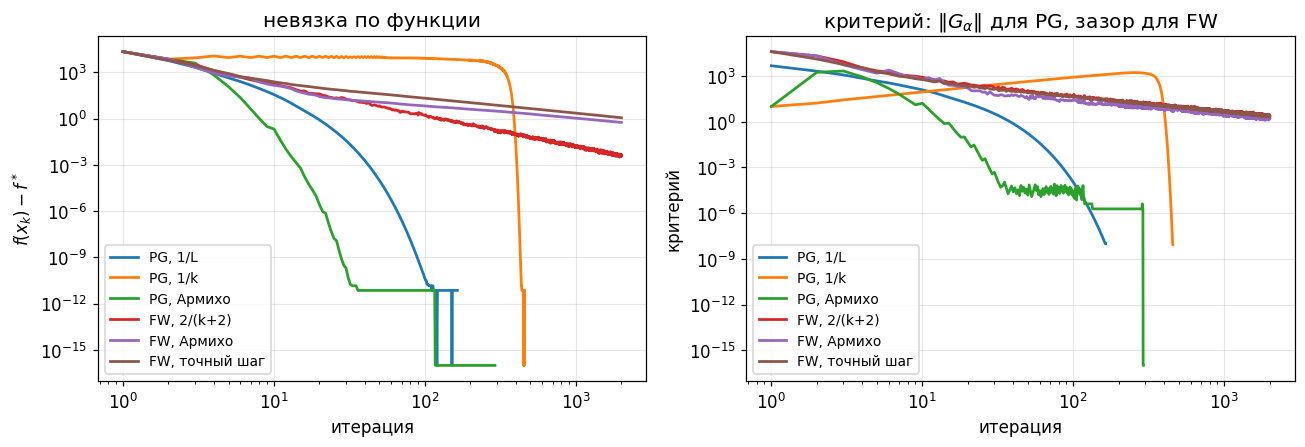

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
plot_traces([tr for _, tr in res], fstar=fstar, ax=axes[0], title="невязка по функции")
plot_traces([tr for _, tr in res], ax=axes[1],
            title=r"критерий: $\|G_\alpha\|$ для PG, зазор для FW")
axes[1].set_yscale("log")
plt.tight_layout()

Разрыв огромный: проекция на куб стоит столько же, сколько LMO, зато решение
лежит на грани — активны 138 ограничений из 200 — и условный градиент вынужден
приближать его бесконечной комбинацией вершин. Почему именно так, разбираем в п. 5.

### 4.1. Зазор как оценка невязки

Проверяем, насколько зазор $g_k$ завышает настоящую невязку $f(x_k)-f^*$.

зазор всегда не меньше невязки: True
g_k / (f(x_k) - f*): медиана 2.0, минимум 1.7, максимум 2.9


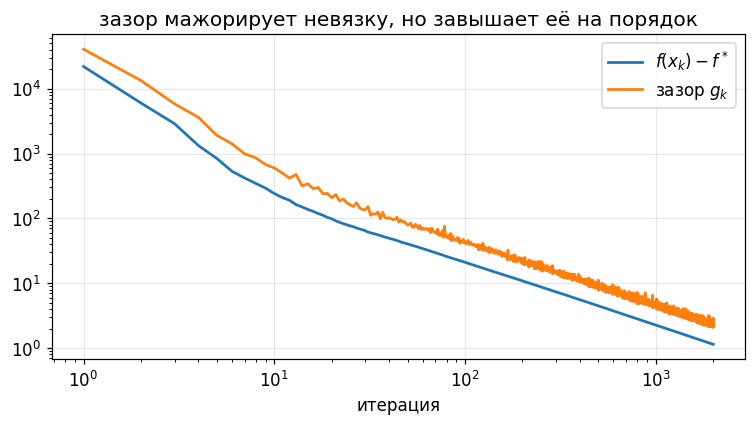

In [10]:
tr_fw = res[-1][1]
resid = tr_fw.fs - fstar
ok = resid > 1e-10 * max(1.0, abs(fstar))     # где невязка ещё не шум округления
ratio = tr_fw.crit[ok] / resid[ok]
print("зазор всегда не меньше невязки:", bool(np.all(tr_fw.crit[:-1] >= resid[:-1] - 1e-12)))
print(f"g_k / (f(x_k) - f*): медиана {np.median(ratio):.1f}, "
      f"минимум {ratio.min():.1f}, максимум {ratio.max():.1f}")

plt.figure(figsize=(7, 4))
plt.loglog(np.arange(1, ok.sum() + 1), resid[ok], label=r"$f(x_k) - f^*$")
plt.loglog(np.arange(1, ok.sum() + 1), tr_fw.crit[ok], label=r"зазор $g_k$")
plt.xlabel("итерация")
plt.legend()
plt.title("зазор мажорирует невязку, но завышает её на порядок")
plt.tight_layout()

## 5. Эксперимент 2: почему Франк–Вольф «зигзагует»

Скорость $O(1/k)$ у метода условного градиента не улучшается даже для сильно
выпуклой $f$, если решение лежит на грани допустимого множества, а не в вершине.
Смотрим на двумерной картинке: $\min \tfrac12\|x - c\|^2$ на шаре $\ell_1$.

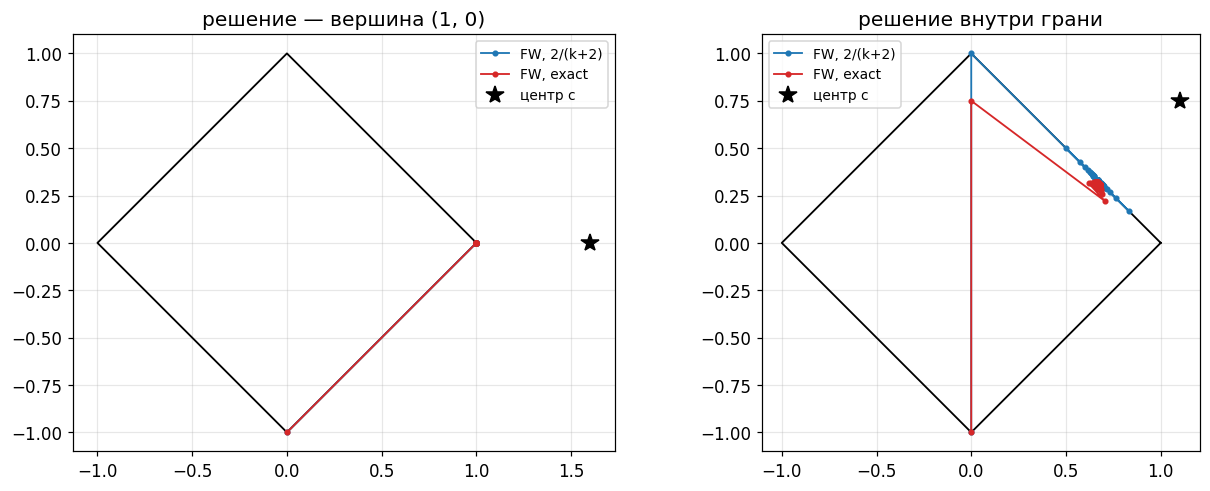

In [11]:
def fw_traj(c, x0, iters=30, step="2/(k+2)"):
    xs = [np.array(x0, float)]
    x = xs[0]
    for k in range(iters):
        g = x - c
        s = lmo_l1(g, 1.0)
        d = s - x
        if d @ d < 1e-30:
            xs.append(x)
            continue
        if step == "2/(k+2)":
            a = 2.0 / (k + 2)
        else:
            a = float(np.clip(-(g @ d) / (d @ d), 0, 1))
        x = x + a * d
        xs.append(x)
    return np.array(xs)


fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, c, ttl in zip(axes, [np.array([1.6, 0.0]), np.array([1.1, 0.75])],
                      ["решение — вершина (1, 0)", "решение внутри грани"]):
    ax.plot([1, 0, -1, 0, 1], [0, 1, 0, -1, 0], "k-", lw=1.2)
    for step, color in [("2/(k+2)", "tab:blue"), ("exact", "tab:red")]:
        tj = fw_traj(c, [0.0, -1.0], 40, step)
        ax.plot(tj[:, 0], tj[:, 1], "o-", ms=3, lw=1.2, color=color,
                label=f"FW, {step}")
    ax.plot(*c, "k*", ms=12, label="центр c")
    ax.set_title(ttl)
    ax.set_aspect("equal")
    ax.legend(fontsize=9)
plt.tight_layout()

In [12]:
for c, ttl in [(np.array([1.6, 0.0]), "вершина"), (np.array([1.1, 0.75]), "грань")]:
    tj = fw_traj(c, [0.0, -1.0], 200, "exact")
    x_opt = proj_l1(c, 1.0)
    err = 0.5 * np.sum((tj - c) ** 2, axis=1) - 0.5 * np.sum((x_opt - c) ** 2)
    print(f"{ttl:>8}: f-f* через 10 итераций {err[10]:.2e}, "
          f"через 100 — {err[100]:.2e}, через 200 — {err[200]:.2e}")

 вершина: f-f* через 10 итераций 0.00e+00, через 100 — 0.00e+00, через 200 — 0.00e+00
   грань: f-f* через 10 итераций 1.33e-02, через 100 — 1.80e-03, через 200 — 9.27e-04


В первом случае решение — вершина, метод попадает в неё за конечное число шагов
и невязка падает линейно. Во втором оптимум лежит внутри грани, попасть в него
можно только бесконечной комбинацией вершин — отсюда $O(1/k)$ и зигзаг.
Метод проекции градиента этой разницы не чувствует.

## 6. Эксперимент 3: разреженность итераций на шаре $\ell_1$

$$\min_{\|x\|_1 \le r} \tfrac12\|Ax - b\|_2^2$$

LMO на шаре $\ell_1$ возвращает вершину $\pm r\,e_i$, поэтому после $k$ итераций
в $x_k$ не более $k$ ненулевых компонент. У метода проекции градиента итерация
плотная с самого начала.

In [13]:
rng = np.random.default_rng(5)
n, m, k_true = 1000, 300, 15
A = rng.normal(size=(m, n)) / np.sqrt(m)
x_true = np.zeros(n)
supp = rng.choice(n, k_true, replace=False)
x_true[supp] = rng.normal(size=k_true) * 2
b = A @ x_true + 0.01 * rng.normal(size=m)
r = np.abs(x_true).sum()
L = np.linalg.eigvalsh(A.T @ A).max()

f = lambda x: 0.5 * np.linalg.norm(A @ x - b) ** 2
gradf = lambda x: A.T @ (A @ x - b)
x0 = np.zeros(n)
nnz = lambda x: int(np.sum(np.abs(x) > 1e-8))


def exact_l1(x, d):
    Ad = A @ d
    den = Ad @ Ad
    return 0.0 if den <= 0 else float(np.clip(-(A @ x - b) @ Ad / den, 0, 1))


x_fw, tr_fw = frank_wolfe(f, gradf, lambda g: lmo_l1(g, r), x0, step="exact",
                          exact=exact_l1, max_iter=300, name="FW, точный шаг",
                          extra=nnz)
x_pg, tr_pg = projected_gd(f, gradf, lambda y: proj_l1(y, r), x0, alpha=1 / L,
                           max_iter=300, name="PG, 1/L", extra=nnz)
fstar = min(tr_fw.fs.min(), tr_pg.fs.min()) - 1e-14
supp_true = set(np.nonzero(x_true)[0])
for x_, tr_ in [(x_fw, tr_fw), (x_pg, tr_pg)]:
    supp = set(np.nonzero(np.abs(x_) > 1e-8)[0])
    print(f"{tr_.name:>14}: f = {tr_.fs[-1]:.4e}, ненулей {len(supp):4d}, "
          f"угадано из {k_true} истинных — {len(supp & supp_true):2d}, "
          f"||x - x_true|| = {np.linalg.norm(x_ - x_true):.3f}")

FW, точный шаг: f = 2.1776e-01, ненулей   15, угадано из 15 истинных — 15, ||x - x_true|| = 0.631
       PG, 1/L: f = 1.1104e-02, ненулей   87, угадано из 15 истинных — 15, ||x - x_true|| = 0.105


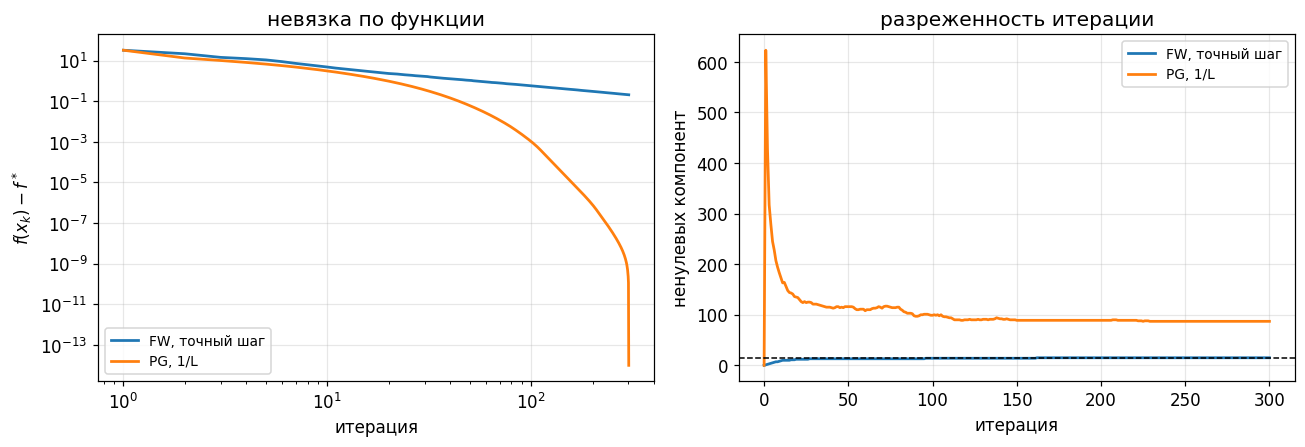

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
plot_traces([tr_fw, tr_pg], fstar=fstar, ax=axes[0], title="невязка по функции")
for tr in [tr_fw, tr_pg]:
    axes[1].plot(tr.extra, label=tr.name)
axes[1].axhline(k_true, color="k", ls="--", lw=1)
axes[1].set_xlabel("итерация")
axes[1].set_ylabel("ненулевых компонент")
axes[1].set_title("разреженность итерации")
axes[1].legend(fontsize=9)
plt.tight_layout()

## 7. Эксперимент 4: шар ядерной нормы

Восстановление матрицы по части наблюдений:

$$\min_{\|X\|_* \le \delta} \tfrac12 \sum_{(i,j)\in\Omega}(X_{ij} - M_{ij})^2,
\qquad \|X\|_* = \sum_i \sigma_i(X).$$

Ядерная норма — выпуклая оболочка ранга на спектральном шаре, поэтому
ограничение на неё работает как регуляризация на низкий ранг.

Разница в цене оракулов решающая:

* проекция: полное SVD, $O(\min(p,q)pq)$, плюс проекция спектра на шар $\ell_1$;
* LMO: $\min_{\|S\|_*\le\delta}\langle G, S\rangle = -\delta\, u_1 v_1^\top$,
  где $u_1, v_1$ — старшая сингулярная пара $G$; считается итерационно по
  матрично-векторным произведениям.

Двойственность норм: $\max_{\|S\|_*\le \delta}\langle -G, S\rangle
= \delta\,\|G\|_2 = \delta\,\sigma_{\max}(G)$ — линейный оракул для шара
ядерной нормы считает спектральную норму градиента, сопряжённую к ядерной.

In [15]:
rng = np.random.default_rng(2)
p = q = 500
rank_true = 5
Mtrue = (rng.normal(size=(p, rank_true)) @ rng.normal(size=(rank_true, q))) / np.sqrt(rank_true)
mask = rng.random((p, q)) < 0.15
rows, cols = np.nonzero(mask)
vals = Mtrue[rows, cols]
test = ~mask
delta = np.linalg.norm(Mtrue, "nuc")
print(f"матрица {p}x{q}, ранг {rank_true}, наблюдений {mask.sum()} "
      f"({100 * mask.mean():.0f}%), delta = ||M||_* = {delta:.1f}")

матрица 500x500, ранг 5, наблюдений 37651 (15%), delta = ||M||_* = 1118.3


In [16]:
def f_mc(X):
    return 0.5 * np.sum((X[rows, cols] - vals) ** 2)


def grad_sparse(X):
    """Градиент разрежен: ненулевой только на наблюдённых позициях."""
    resid = X[rows, cols] - vals
    return sp.coo_matrix((resid, (rows, cols)), shape=(p, q)).tocsr()


def grad_dense(X):
    return np.asarray(grad_sparse(X).todense())


def test_rmse(X):
    return float(np.sqrt(np.mean((X[test] - Mtrue[test]) ** 2)))

Франк–Вольф хранит итерацию как сумму ранг-одних слагаемых: после $k$ шагов
$\mathrm{rank}(X_k) \le k$. Шаг $2/(k+2)$ домножает все накопленные слагаемые на
$1-\alpha_k$ и добавляет одно новое.

In [17]:
def fw_nuclear(max_iter=100, delta=delta):
    X = np.zeros((p, q))
    tr = Trace("FW, LMO (ранг-1)")
    for k in range(max_iter):
        G = grad_sparse(X)
        u, v = lmo_nuclear(G, delta)
        gap = float(G.multiply(X).sum() - (u @ G.dot(v)))
        tr.add(f_mc(X), gap, test_rmse(X))
        a = 2.0 / (k + 2)
        X *= (1 - a)
        X += a * np.outer(u, v)
    tr.add(f_mc(X), gap, test_rmse(X))
    return X, tr


def pg_nuclear(max_iter=100, delta=delta, alpha=1.0):
    X = np.zeros((p, q))
    tr = Trace("PG, проекция (полное SVD)")
    for k in range(max_iter):
        Xn = proj_nuclear(X - alpha * grad_dense(X), delta)
        tr.add(f_mc(X), np.linalg.norm(X - Xn) / alpha, test_rmse(X))
        X = Xn
    tr.add(f_mc(X), 0.0, test_rmse(X))
    return X, tr


X_fw, tr_fw = fw_nuclear(600)
X_pg, tr_pg = pg_nuclear(60)
for X, tr in [(X_fw, tr_fw), (X_pg, tr_pg)]:
    sv = np.linalg.svd(X, compute_uv=False)
    print(f"{tr.name:>28}: f = {tr.fs[-1]:10.3f}, test RMSE = {tr.extra[-1]:.4f}, "
          f"ранг {int(np.sum(sv > 1e-6 * sv[0])):3d}, время {tr.t[-1]:5.1f} с")

            FW, LMO (ранг-1): f =      3.698, test RMSE = 0.0288, ранг 359, время   4.9 с
   PG, проекция (полное SVD): f =     63.047, test RMSE = 0.1817, ранг  48, время   4.2 с


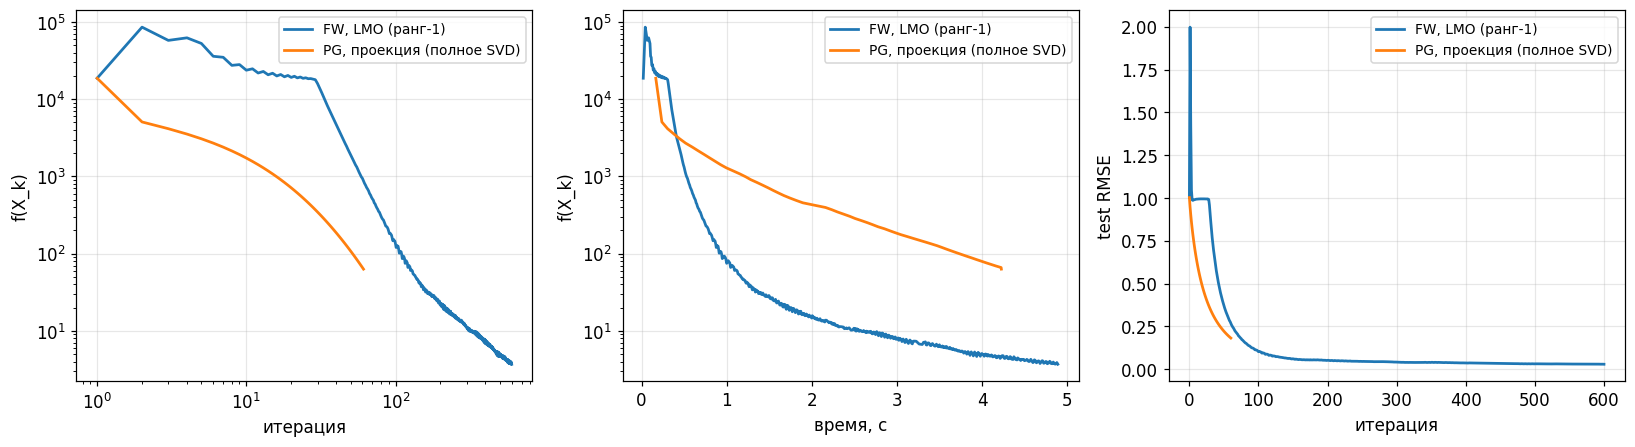

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for tr in [tr_fw, tr_pg]:
    axes[0].loglog(np.arange(1, len(tr.fs) + 1), tr.fs, label=tr.name)
    axes[1].semilogy(tr.t, tr.fs, label=tr.name)
    axes[2].plot(tr.extra, label=tr.name)
axes[0].set_xlabel("итерация"); axes[0].set_ylabel("f(X_k)"); axes[0].legend(fontsize=9)
axes[1].set_xlabel("время, с"); axes[1].set_ylabel("f(X_k)"); axes[1].legend(fontsize=9)
axes[2].set_xlabel("итерация"); axes[2].set_ylabel("test RMSE"); axes[2].legend(fontsize=9)
plt.tight_layout()

### 7.1. Во сколько раз LMO дешевле проекции

In [19]:
print(f"{'размер':>8} {'полное SVD, мс':>16} {'старшая пара, мс':>18} {'отношение':>11}")
for size in [200, 400, 800, 1600]:
    Z = rng.normal(size=(size, size))
    Zs = sp.random(size, size, density=0.15, random_state=0, format="csr")
    t = time.perf_counter(); np.linalg.svd(Z, full_matrices=False); t_full = time.perf_counter() - t
    t = time.perf_counter(); spla.svds(Zs, k=1, tol=1e-6); t_one = time.perf_counter() - t
    print(f"{size:8d} {1e3 * t_full:16.1f} {1e3 * t_one:18.1f} {t_full / t_one:10.0f}x")

  размер   полное SVD, мс   старшая пара, мс   отношение
     200              7.5                2.2          3x
     400             37.3                3.4         11x
     800            239.2                8.6         28x
    1600           1635.2               22.4         73x


Разрыв растёт с размером: проекция — кубическая, LMO — порядка числа ненулей
градиента на одну итерацию Ланцоша. При $p = q = 10^4$ полное SVD уже
нереалистично, а ранг-один шаг Франка–Вольфа остаётся дешёвым.

Цена за это — скорость $O(1/k)$ и ранг итерации, растущий линейно по числу шагов:
для высокой точности приходится добавлять away-steps или переходить к
факторизованным методам.

## Итог

| множество | проекция | LMO |
|---|---|---|
| куб $[l, u]^n$ | покоординатно, $O(n)$ | покоординатно, $O(n)$ |
| симплекс | сортировка, $O(n\log n)$ | $\arg\min_i g_i$, $O(n)$ |
| шар $\ell_1$ | через симплекс, $O(n\log n)$ | $\arg\max_i \lvert g_i \rvert$, $O(n)$ |
| шар $\ell_2$ | нормировка, $O(n)$ | нормировка, $O(n)$ |
| шар ядерной нормы | полное SVD, $O(pq\min(p,q))$ | старшая сингулярная пара |
| $\mathbb{R}^n_+$ | $\max(x, 0)$ | не существует (LP неограничена) |

* Метод проекции градиента наследует скорости безусловного градиентного спуска
  ($O(1/k)$, линейная при сильной выпуклости), но требует проекции.
* Франк–Вольф даёт $O(1/k)$ без проекции, бесплатный сертификат точности и
  структурные итерации: разреженные или низкого ранга.
* Выбор между ними определяется не скоростью сходимости, а тем, какой из двух
  оракулов на данном множестве дешевле.